# 6 · Multistage cascades, energy and cost

A single stage cannot give high purity *and* high recovery at the same time. Cascades with recycle
work around this at the price of more area and more compression. This notebook uses biogas
upgrading at the conditions of Makaruk et al. (2010): 1000 Nm³/h of raw biogas with 60 % CH₄,
compressed to 10 bar, a polyimide membrane with CO₂ permeance 100 GPU and CO₂/CH₄ = 35, and a
target of 98 % CH₄ in the product.

Layouts (each stage can use any flow pattern):

* **Single stage**
* **Two-stage stripping**: retentate 1 is polished in stage 2, and permeate 2 is recompressed and recycled.
* **Two-stage enriching**: permeate 1 is recompressed and purified in stage 2, and retentate 2 is recycled.
* **Three-stage**: retentate 1 → stage 2 (biomethane); permeate 1 → stage 3 at the stage-1
  permeate pressure (CO₂ off-gas); permeate 2 and retentate 3 are recycled to the compressor.

Recycles are converged by Wegstein-accelerated successive substitution.

**Energy** is computed for intercooled two-stage compression with Makaruk's efficiencies
(isentropic 0.80 × mechanical 0.90 = 0.72).
**Cost** uses the transparent placeholder values in `CostAssumptions`. They show how the trade-off
*moves* with stage cut, not what a plant would cost; replace them with your own figures.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: zip unzipped in /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if TOOLKIT is None and IN_COLAB:
    print("Looking for the toolkit in your Google Drive (approve the access request)...")
    from google.colab import drive
    drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
    if TOOLKIT is None:
        print("Not found in Drive. Choose gas-membrane-stagecut-toolkit.zip to upload:")
        import zipfile
        from google.colab import files
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
        TOOLKIT = _find_toolkit()
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "the unzipped gas-membrane-stagecut-toolkit folder.")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


In [2]:
m = Membrane(MEMBRANE_PRESETS["Polyimide CO2/CH4, a=35 (Makaruk 2010)"])
xf = FEED_PRESETS["biogas, 60% CH4 (Makaruk 2010)"]
F = nm3h_to_mols(1000)
ea = EnergyAssumptions(eta_compressor=0.8 * 0.9)
ca = CostAssumptions()
pattern = "cross_flow"      # fast; use "countercurrent" for hollow fibres (slower)
pd.Series(vars(ca), name="value").to_frame()

,value
membrane_cost_per_m2,50.00
membrane_life_years,5.00
skid_cost_per_m2,250.00
compressor_cost_per_kW,1500.00
vacuum_cost_per_kW,1500.00
interest_rate,0.08
plant_life_years,20.00
maintenance_fraction,0.03
electricity_per_kWh,0.10
hours_per_year,8000.00


## Four layouts side by side

In [3]:
S = lambda th, ph, pl: StageSpec(th, ph, pl, pattern)
cases = {
    "single stage": single_stage(m, xf, F, S(0.533, 10, 1), ea=ea),
    "two-stage stripping": two_stage_stripping(m, xf, F, S(0.330, 10, 1), S(0.335, 10, 1), ea=ea),
    "two-stage enriching": two_stage_enriching(m, xf, F, S(0.50, 10, 1), S(0.70, 10, 1), ea=ea),
    "three-stage": three_stage(m, xf, F, S(0.40, 10, 2), S(0.30, 10, 1), S(0.70, 2, 1), ea=ea),
}
rows = {}
for name, r in cases.items():
    s = r.products["slow-gas product"]
    rows[name] = {"CH4 purity": r.purity(s, "CH4"), "CH4 recovery": r.recovery(s, "CH4"),
                  "recycle / feed": r.recycle_ratio(), "area (m2)": r.total_area,
                  "power (kW)": r.total_power_kW,
                  "kWh per Nm3 product": r.total_power_kW / mols_to_nm3h(r.streams[s].sum()),
                  "kWh per t CH4": specific_energy_kWh_per_tonne(r, s, "CH4"),
                  "USD per t CH4 (indicative)": specific_cost_per_tonne(r, s, "CH4", ca)}
summary = pd.DataFrame(rows).T
summary.round(3)

,CH4 purity,CH4 recovery,recycle / feed,area (m2),power (kW),kWh per Nm3 product,kWh per t CH4,USD per t CH4 (indicative)
single stage,0.980,0.763,0.000,2210.761,112.232,0.240,342.617,78.976
two-stage stripping,0.980,0.938,0.289,2777.727,144.722,0.252,359.177,81.820
two-stage enriching,0.981,0.962,0.176,3261.661,178.252,0.303,431.395,96.197
three-stage,0.980,0.980,0.429,6721.197,154.016,0.257,366.127,131.470


In [4]:
print(cases["three-stage"].summary())
cases["three-stage"].stream_table().round(4)

three-stage: converged in 37 iterations; recycle/feed = 0.429
  total area 6721 m2, total power 154 kW
  fast-gas product (permeate 3): 4.957 mol/s; CO2 0.9693, CH4 0.0307
  slow-gas product (retentate 2): 7.436 mol/s; CO2 0.0205, CH4 0.9795
  stage 1: cross_flow, theta 0.400, area 1681 m2, 10/2 bar
  stage 2: cross_flow, theta 0.300, area 2013 m2, 10/1 bar
  stage 3: cross_flow, theta 0.700, area 3028 m2, 2/1 bar


,flow_mol_s,y_CO2,y_CH4
stream,,,
feed,12.3930,0.4000,0.6000
stage 1 feed,17.7044,0.4302,0.5698
permeate 1,7.0817,0.8426,0.1574
retentate 1,10.6226,0.1553,0.8447
retentate 2,7.4358,0.0205,0.9795
permeate 3,4.9572,0.9693,0.0307
recycle (permeate 2),3.1868,0.4700,0.5300
recycle (retentate 3),2.1245,0.5469,0.4531


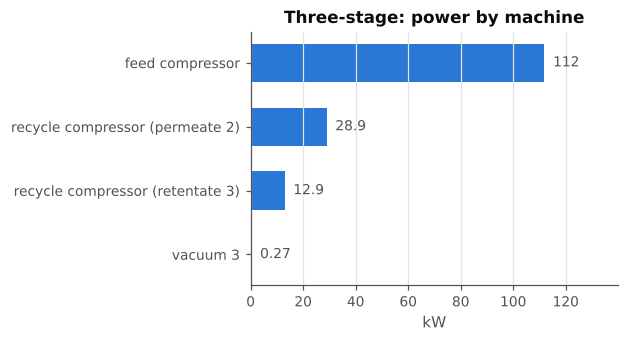

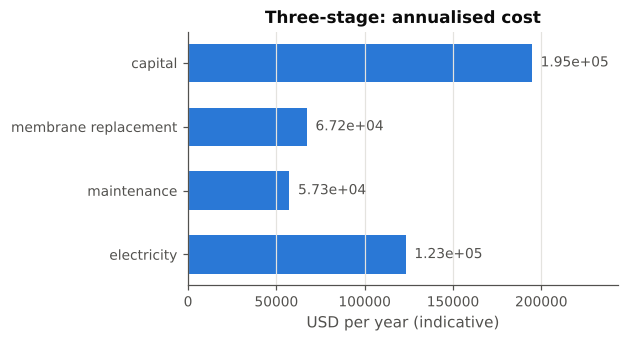

In [5]:
r = cases["three-stage"]
bar_breakdown(list(r.power_kW), list(r.power_kW.values()), "kW", "Three-stage: power by machine"); plt.show()
c = {k.replace("_USD_per_yr", "").replace("_", " "): v for k, v in r.cost.items() if k.endswith("per_yr") and not k.startswith("total")}
bar_breakdown(list(c), list(c.values()), "USD per year (indicative)", "Three-stage: annualised cost"); plt.show()

**Reading the table.** Every layout here was tuned to give about 98 % CH₄.
- **Single stage:** reaches that purity only by losing about a quarter of the methane to the permeate.
- **Two-stage stripping:** recycling the second permeate raises methane recovery to about 94 %. This is the layout Makaruk et al. recommend.
- **Two-stage enriching:** reaches about 96 % recovery. The second compressor makes its power higher, but it also sends a purer CO₂ stream out of the plant.
- **Three-stage:** recovers about 98 %, but needs much more membrane area, because stage 3 runs at a low pressure ratio of 2.

The specific power of about 0.25–0.3 kWh per Nm³ of product is close to the 0.3 kWh/Nm³
Makaruk et al. report. Notebook 07 checks this case in detail.

## Stage cut of the first stage: where is the optimum?

The stage-2 and stage-3 stage cuts are held fixed while the stage-1 stage cut is swept.

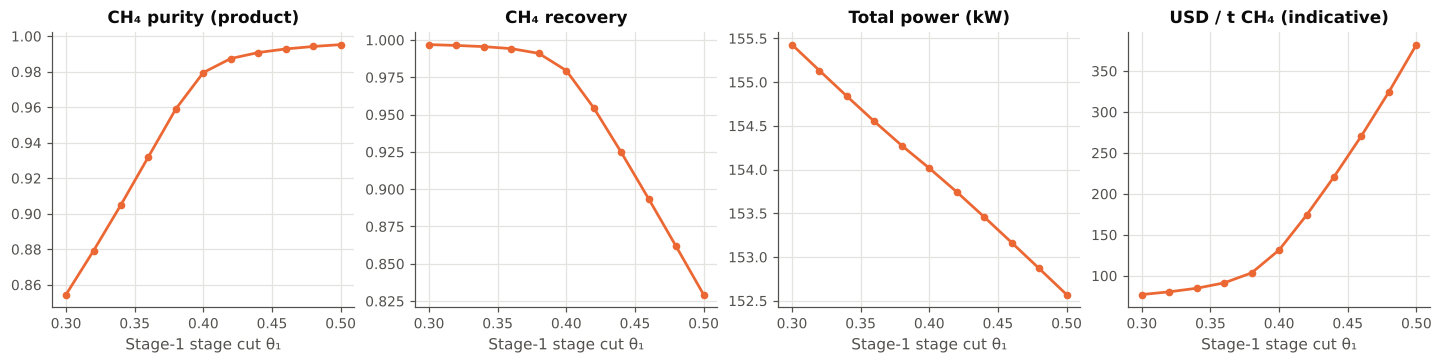

,theta1,purity,recovery,area,power,cost
0,0.30,0.8545,0.9969,2535.7288,155.4289,77.0870
1,0.32,0.8791,0.9964,2803.6276,155.1322,80.4061
2,0.34,0.9051,0.9956,3153.4569,154.8385,84.7786
3,0.36,0.9321,0.9942,3672.6461,154.5503,91.3391
4,0.38,0.9591,0.9910,4624.4012,154.2745,103.5608
5,0.40,0.9795,0.9795,6721.1966,154.0159,131.4703
6,0.42,0.9874,0.9545,9716.2571,153.7445,174.0701
7,0.44,0.9908,0.9247,12771.3561,153.4582,220.8977
8,0.46,0.9928,0.8935,15802.3993,153.1655,270.9399
9,0.48,0.9942,0.8617,18812.8276,152.8693,324.5550


In [6]:
rows = []
for th1 in np.linspace(0.3, 0.5, 11):
    r = three_stage(m, xf, F, S(th1, 10, 2), S(0.30, 10, 1), S(0.70, 2, 1), ea=ea)
    rows.append(dict(theta1=th1, purity=r.purity("retentate 2", "CH4"),
                     recovery=r.recovery("retentate 2", "CH4"), area=r.total_area,
                     power=r.total_power_kW, cost=specific_cost_per_tonne(r, "retentate 2", "CH4", ca)))
sw = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2), constrained_layout=True)
for a, col, ttl in zip(ax, ["purity", "recovery", "power", "cost"],
                       ["CH₄ purity (product)", "CH₄ recovery", "Total power (kW)", "USD / t CH₄ (indicative)"]):
    a.plot(sw["theta1"], sw[col], color=COLORS[pattern], marker="o", ms=4)
    a.set_title(ttl); a.set_xlabel("Stage-1 stage cut θ₁")
plt.show()
sw.round(4)

## Interactive three-stage design

In [7]:
def explore(theta1=0.40, theta2=0.30, theta3=0.7, p_feed=10.0, p_mid=2.0, pattern="cross_flow"):
    r = three_stage(m, xf, F, StageSpec(theta1, p_feed, p_mid, pattern),
                    StageSpec(theta2, p_feed, 1.0, pattern), StageSpec(theta3, p_mid, 1.0, pattern), ea=ea)
    display(Markdown(
        f"**Biomethane**: CH₄ {r.purity('retentate 2','CH4'):.4f}, recovery {r.recovery('retentate 2','CH4'):.4f}  \n"
        f"**Off-gas**: CO₂ {r.purity('permeate 3','CO2'):.4f}, CH₄ slip {1-r.recovery('retentate 2','CH4'):.4f} of feed CH₄  \n"
        f"Area {r.total_area:,.0f} m² · power {r.total_power_kW:,.1f} kW · recycle/feed {r.recycle_ratio():.3f} · "
        f"{specific_energy_kWh_per_tonne(r,'retentate 2','CH4'):,.0f} kWh/t CH₄ · "
        f"{specific_cost_per_tonne(r,'retentate 2','CH4', ca):,.0f} USD/t CH₄ (indicative)"))
    display(r.stream_table().round(4))

w.interact_manual(explore,
                  theta1=w.FloatSlider(value=0.40, min=0.15, max=0.6, step=0.01, description="θ₁"),
                  theta2=w.FloatSlider(value=0.30, min=0.03, max=0.5, step=0.01, description="θ₂"),
                  theta3=w.FloatSlider(value=0.70, min=0.3, max=0.95, step=0.01, description="θ₃"),
                  p_feed=w.FloatSlider(value=10, min=4, max=30, step=0.5, description="p feed"),
                  p_mid=w.FloatSlider(value=2, min=1.25, max=8, step=0.25, description="p perm 1"),
                  pattern=w.Dropdown(options=["cross_flow", "countercurrent", "cocurrent", "well_mixed"]));

interactive(children=(FloatSlider(value=0.4, description='θ₁', max=0.6, min=0.15, step=0.01), FloatSlider(valu…